<a href="https://colab.research.google.com/github/mers2727/mineria-textos-esperanto/blob/main/Practica_Esperanto.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Clasificación de textos en Esperanto
**Minería de Textos · 4º INF-A · 2026/2027**
**Equipo:** Mikel Echarri Richard · Joaquín Álvarez Julia · Víctor Hernández Enciso

## Índice
1. Configuración
2. Fase 1 — Dataset
3. Fase 2 — Modelo de NLP
4. Fase 3 — Clasificación y páginas web
5. Conclusiones


## 1. Configuración
Todos los parámetros que se pueden cambiar están en la celda siguiente. La semilla está fijada para que el resultado sea reproducible.

In [1]:
# ===== 1. Configuración =====
# Librerías estándar de Python
import re                  # expresiones regulares: limpieza de texto y tokenizador
import time                # pausas entre peticiones a Wikipedia
import random              # muestreos aleatorios (con semilla)
import unicodedata         # normalizar letras del esperanto (ĉ, ĝ, ŭ...)
from collections import Counter   # contar palabras

# Librerías vistas en clase (apartado 3.1 del enunciado)
import numpy as np
import pandas as pd        # tablas y el CSV del dataset
import requests            # peticiones al API de Wikipedia y a páginas web
import matplotlib.pyplot as plt   # gráficos
import sklearn             # modelo de clasificación (Fase 3)
import bs4                 # BeautifulSoup: web scraping (Fase 3)

# Semilla fija: los muestreos y el modelo darán siempre el mismo resultado
SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)

# True: genera el dataset desde Wikipedia. False: lee el CSV ya publicado en GitHub
GENERAR_DATASET = False
URL_REPO = "https://raw.githubusercontent.com/mers2727/mineria-textos-esperanto/main/"

# Versiones de las librerías, porque algún resultado puede variar entre versiones
for nombre, modulo in [("pandas", pd), ("numpy", np), ("requests", requests),
                       ("scikit-learn", sklearn), ("beautifulsoup4", bs4)]:
    print(f"{nombre:15s} {modulo.__version__}")

pandas          2.2.3
numpy           2.4.6
requests        2.32.4
scikit-learn    1.6.1
beautifulsoup4  4.13.5


## 2. Fase 1 — Dataset

### 2.1 Selección de temáticas
Elegimos **`fiziko` (física), `kemio` (química) y `biologio` (biología)**, uno de los ejemplos del enunciado.

* **Son cercanas:** las tres son ciencias naturales y comparten vocabulario (*energio*, *molekulo*, *atomo*, *akvo*),
  así que el problema no es trivial.
* **Hay datos suficientes:** antes de decidir lo comprobamos con el API de Wikipedia en Esperanto (celda siguiente).
* **Riesgo que asumimos:** hay temas a caballo entre dos clases (bioquímica, biofísica). Los trataremos en la limpieza.

In [2]:
# ===== 2.1 Comprobación de que hay datos =====
API = "https://eo.wikipedia.org/w/api.php"

# Wikipedia pide que los programas se identifiquen con un User-Agent con contacto
sesion = requests.Session()
sesion.headers["User-Agent"] = ("CUNEF-MineriaTextos/1.0 (practica academica; "
                                "https://github.com/mers2727/mineria-textos-esperanto)")

CATEGORIAS = {"fiziko": "Fiziko", "kemio": "Kemio", "biologio": "Biologio"}   # etiqueta -> categoría de Wikipedia


def contar_miembros(categoria):
    """Cuántos artículos y subcategorías cuelgan directamente de una categoría (máx. 500, solo para explorar)."""
    parametros = {"action": "query", "list": "categorymembers", "cmtitle": f"Kategorio:{categoria}",
                  "cmtype": "page|subcat", "cmlimit": 500, "format": "json"}
    try:
        datos = sesion.get(API, params=parametros, timeout=30).json()
    except (requests.RequestException, ValueError):
        return None, None                      # si Wikipedia falla, el cuaderno sigue
    miembros = datos.get("query", {}).get("categorymembers", [])
    articulos = sum(1 for m in miembros if m["ns"] == 0)       # ns 0 = artículo
    subcategorias = sum(1 for m in miembros if m["ns"] == 14)  # ns 14 = categoría
    return articulos, subcategorias


exploracion = pd.DataFrame(
    [(etiqueta, *contar_miembros(cat)) for etiqueta, cat in CATEGORIAS.items()],
    columns=["clase", "artículos directos", "subcategorías"]).set_index("clase")
print(exploracion)

          artículos directos  subcategorías
clase                                      
fiziko                   256             24
kemio                    150              6
biologio                 114             65


### 2.2 Descarga de artículos
**Fuente:** API de Wikipedia en Esperanto (`eo.wikipedia.org`).

* **Qué artículos:** los de la categoría de cada clase y los de sus subcategorías (un nivel). En `kemio` añadimos
  más categorías de partida porque solo tiene 6 subcategorías.
* **Subcategorías excluidas:** las que no son la ciencia en sí (biografías, listas, premios, historia) y las que
  mezclan dos clases (bioquímica, biofísica, química cuántica).
* **Artículos ambiguos:** si un artículo aparece en dos clases, lo quitamos de ambas.
* **Tamaño:** como mucho 250 artículos por clase, elegidos al azar con la semilla.
* **Robustez:** si Wikipedia responde "demasiadas peticiones" (429) o falla la red, esperamos y reintentamos.

In [3]:
# ===== 2.2 Funciones de descarga =====
# Categorías de Wikipedia de las que partimos para cada clase
SEMILLAS = {
    "fiziko":   ["Fiziko"],
    "kemio":    ["Kemio", "Konceptoj en kemio", "Kemiaj elementoj", "Organika kemio", "Neorganika kemio"],
    "biologio": ["Biologio"],
}
# Si el nombre de una subcategoría contiene alguno de estos trozos, no se usa
SUBCATS_EXCLUIDAS = ["biograf", "listoj", "fizikistoj", "kemiistoj", "biologoj", "historio", "organizaĵoj",
                     "premioj", "biokemio", "biofiziko", "kvantuma kemio", "faŭno", "flaŭro"]
MAX_ARTICULOS_POR_CLASE = 250
PAUSA = 0.3    # segundos entre descargas, para no saturar Wikipedia


def pedir(parametros, intentos=4):
    """Petición al API de Wikipedia. Reintenta si hay error; devuelve None si no lo consigue."""
    parametros = {**parametros, "format": "json", "formatversion": 2}
    for intento in range(intentos):
        try:
            respuesta = sesion.get(API, params=parametros, timeout=30)
            if respuesta.status_code in (429, 503):        # "demasiadas peticiones" o servidor ocupado
                time.sleep(2 * 2 ** intento)               # esperamos 2, 4, 8... segundos
                continue
            respuesta.raise_for_status()                   # otros errores HTTP -> excepción
            return respuesta.json()
        except (requests.RequestException, ValueError):
            time.sleep(2 ** intento)
    return None


def miembros(categoria, tipo):
    """Títulos de los artículos (tipo='page') o subcategorías (tipo='subcat') de una categoría.
    El API devuelve los resultados por tandas: seguimos pidiendo mientras haya 'continue'."""
    titulos, continuar = [], {}
    while True:
        datos = pedir({"action": "query", "list": "categorymembers", "cmtitle": f"Kategorio:{categoria}",
                       "cmtype": tipo, "cmlimit": 500, **continuar})
        if datos is None or "error" in datos:              # sin conexión o la categoría no existe
            return titulos
        titulos += [m["title"] for m in datos["query"]["categorymembers"]]
        if "continue" not in datos:
            return titulos
        continuar = datos["continue"]


def articulos_de_clase(semillas):
    """Artículos de las categorías semilla y de sus subcategorías (un nivel), sin las excluidas."""
    articulos = set()
    for categoria in semillas:
        articulos.update(miembros(categoria, "page"))
        for sub in miembros(categoria, "subcat"):
            nombre = sub.split(":", 1)[1]                  # "Kategorio:Optiko" -> "Optiko"
            if not any(trozo in nombre.lower() for trozo in SUBCATS_EXCLUIDAS):
                articulos.update(miembros(nombre, "page"))
    return articulos


def texto_de_articulo(titulo):
    """Texto plano de un artículo (sin HTML ni marcado wiki). Devuelve '' si falla."""
    time.sleep(PAUSA)
    datos = pedir({"action": "query", "prop": "extracts", "explaintext": 1, "redirects": 1, "titles": titulo})
    if datos is None:
        return ""
    paginas = datos.get("query", {}).get("pages", [])
    return paginas[0].get("extract", "") if paginas else ""

In [4]:
# ===== 2.2 Descarga (solo si GENERAR_DATASET = True) =====
if GENERAR_DATASET:
    inicio = time.time()
    candidatos = {clase: articulos_de_clase(semillas) for clase, semillas in SEMILLAS.items()}

    # Un artículo que está en dos clases es ambiguo: lo quitamos de todas
    conteo = Counter(titulo for articulos in candidatos.values() for titulo in articulos)
    ambiguos = {titulo for titulo, veces in conteo.items() if veces > 1}

    rng = random.Random(SEMILLA)
    textos = {}                                            # clase -> {título: texto}
    for clase, articulos in candidatos.items():
        lista = sorted(articulos - ambiguos)               # sorted: mismo orden en cada ejecución
        rng.shuffle(lista)
        elegidos = lista[:MAX_ARTICULOS_POR_CLASE]
        textos[clase] = {titulo: texto_de_articulo(titulo) for titulo in elegidos}
        vacios = sum(1 for texto in textos[clase].values() if not texto)
        print(f"{clase:9s} {len(articulos):5d} candidatos -> {len(elegidos)} descargados ({vacios} vacíos)")

    print(f"Artículos ambiguos eliminados: {len(ambiguos)}")
    print(f"Tiempo: {time.time() - inicio:.0f} s")

### 2.3 División en párrafos y limpieza
Cada línea del texto de un artículo es un párrafo. Para cumplir el **contrato de datos**:

* **Limpieza:** quitamos referencias (`[1]`), URLs, restos de HTML y comillas dobles, y cambiamos `;` por `,`.
* **Secciones que no son prosa:** descartamos *Referencoj*, *Eksteraj ligiloj*, *Vidu ankaŭ*, etc.
* **Párrafos válidos:** al menos 100 caracteres y 15 palabras, que empiecen como una frase (mayúscula o cifra) y
  acaben en punto, y que sean texto en su mayoría (no tablas ni fórmulas).
* **Tope por artículo:** como mucho 10 párrafos por artículo, elegidos al azar. Así ningún artículo largo domina
  su clase, y su ruido pesa menos.
* **Repetidos:** si un mismo párrafo aparece en dos clases, lo quitamos; si se repite en la misma clase, dejamos uno.

In [5]:
# ===== 2.3 Funciones de limpieza =====
SECCIONES_EXCLUIDAS = {"referencoj", "eksteraj ligiloj", "vidu ankaŭ", "notoj", "literaturo",
                       "bibliografio", "fontoj", "ligiloj", "legu ankaŭ"}
LONGITUD_MIN = 100               # caracteres
PALABRAS_MIN = 15
MAX_PARRAFOS_POR_ARTICULO = 10


def limpiar_parrafo(parrafo):
    """Deja el párrafo limpio según el contrato de datos."""
    parrafo = unicodedata.normalize("NFC", parrafo)               # ĉ siempre como una sola letra
    parrafo = re.sub(r"\[[^\]]*\]", "", parrafo)                   # referencias: [1], [citaĵo bezonata]
    parrafo = re.sub(r"https?://\S+|www\.\S+", "", parrafo)        # enlaces
    parrafo = re.sub(r"<[^>]+>", "", parrafo)                      # restos de etiquetas HTML
    parrafo = re.sub(r"\(\s*\)", "", parrafo)                      # paréntesis que se quedan vacíos
    parrafo = parrafo.replace(";", ",").replace('"', "")           # ';' es el separador del CSV
    parrafo = re.sub(r"\s+", " ", parrafo).strip()                 # espacios repetidos
    return re.sub(r"\s+([,.:!?])", r"\1", parrafo)                 # espacio antes de un signo


def es_parrafo_valido(parrafo):
    """True si es un párrafo de verdad: largo, frase completa y casi todo letras."""
    if len(parrafo) < LONGITUD_MIN or len(parrafo.split()) < PALABRAS_MIN:
        return False
    if not (parrafo[0].isupper() or parrafo[0].isdigit() or parrafo[0] in "«("):
        return False                                               # empieza en minúscula: frase cortada
    if parrafo[-1] not in ".!?»)":
        return False                                               # no acaba como una frase
    return sum(c.isalpha() for c in parrafo) / len(parrafo) >= 0.7  # tablas y fórmulas tienen pocas letras


def parrafos_de_texto(texto):
    """Párrafos válidos de un artículo, saltando las secciones que no son prosa."""
    resultado, seccion = [], ""
    for linea in texto.split("\n"):
        linea = linea.strip()
        encabezado = re.fullmatch(r"=+\s*(.*?)\s*=+", linea)      # "== Historio =="
        if encabezado:
            seccion = encabezado.group(1).lower()
        elif linea and seccion not in SECCIONES_EXCLUIDAS:
            parrafo = limpiar_parrafo(linea)
            if es_parrafo_valido(parrafo):
                resultado.append(parrafo)
    return resultado


# Pruebas rápidas de la limpieza
assert limpiar_parrafo("La atomo [1] estas malgranda; vidu https://x.org .") == "La atomo estas malgranda, vidu."
assert not es_parrafo_valido("notis ke ĉi tiu procezo estas grava sub kondiĉoj kiel altaj temperaturoj kaj premoj en la naturo.")
print("Pruebas de limpieza: OK")

Pruebas de limpieza: OK


In [6]:
# ===== 2.3 Construcción de la tabla de párrafos =====
if GENERAR_DATASET:
    filas = [{"text": parrafo, "class": clase, "article": titulo}
             for clase, articulos in textos.items()
             for titulo, texto in articulos.items()
             for parrafo in parrafos_de_texto(texto)]
    df_completo = pd.DataFrame(filas)

    # Repetidos: si un párrafo está en dos clases se quita; si no, se deja una copia
    en_varias_clases = df_completo.groupby("text")["class"].transform("nunique") > 1
    df_completo = df_completo[~en_varias_clases].drop_duplicates(subset="text").reset_index(drop=True)
    print("Párrafos válidos por clase:  ", df_completo["class"].value_counts().to_dict())

    # Tope por artículo: barajamos (con semilla) y nos quedamos con los 10 primeros de cada artículo
    df_tope = (df_completo.sample(frac=1, random_state=SEMILLA)
               .groupby("article").head(MAX_PARRAFOS_POR_ARTICULO).reset_index(drop=True))
    print("Tras el tope por artículo:   ", df_tope["class"].value_counts().to_dict())
    print("Artículos con párrafos:      ", df_tope.groupby("class")["article"].nunique().to_dict())

In [7]:
# ===== 2.2 Leer el dataset publicado =====
df_publicado = None
if not GENERAR_DATASET:
    try:
        df_publicado = pd.read_csv(URL_REPO + "dataset_con_articulos.csv", sep=";", encoding="utf-8")
        print(f"Dataset leído de GitHub: {len(df_publicado)} párrafos")
    except Exception as error:                     # sin conexión, fichero inexistente, CSV roto...
        print(f"No se pudo leer el CSV de GitHub ({type(error).__name__}). Lo generamos desde Wikipedia.")
        GENERAR_DATASET = True                     # plan B: las celdas siguientes lo generan

Dataset leído de GitHub: 1800 párrafos


### 2.4 Dataset final y contrato de datos
* **Equilibrado:** 600 párrafos por clase, elegidos al azar con la semilla. Con clases del mismo tamaño, accuracy y
  F1 macro son fáciles de interpretar, y el modelo no se inclina hacia la clase más grande.
* **Dos ficheros:** `dataset.csv` es el contrato (`text;class`). `dataset_con_articulos.csv` añade la columna
  `article`, que necesitaremos en la Fase 3 para que ningún artículo tenga párrafos en train y en test a la vez.
* **Comprobación del contrato:** lo verificamos con `assert` releyendo el fichero guardado.
* **Publicación:** ambos ficheros están en GitHub; con `GENERAR_DATASET = False` se leen de ahí.

'dataset.csv' cumple el contrato: 1800 párrafos, {'kemio': 600, 'fiziko': 600, 'biologio': 600}


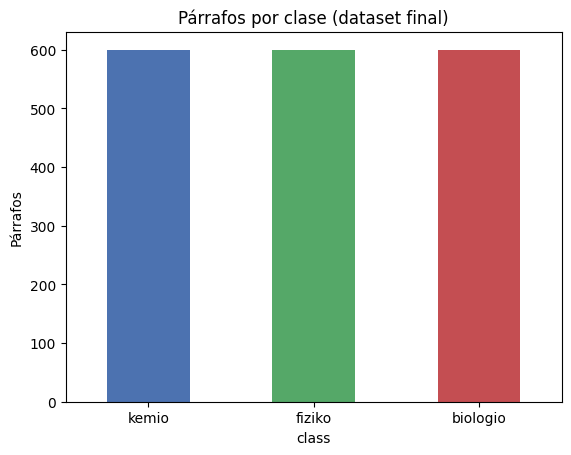

In [8]:
# ===== 2.4 Equilibrado, guardado y comprobación del contrato =====
ARCHIVO_DATASET = "dataset.csv"                          # contrato: text;class
ARCHIVO_DATASET_ARTICULOS = "dataset_con_articulos.csv"  # igual + columna article
PARRAFOS_POR_CLASE = 600


def equilibrar(df, n):
    """Mismo número de párrafos en cada clase (n, o el de la clase más pequeña si tiene menos)."""
    n = min(n, df["class"].value_counts().min())
    return (df.groupby("class").sample(n=n, random_state=SEMILLA)   # n al azar de cada clase
              .sample(frac=1, random_state=SEMILLA)                 # mezclamos las clases
              .reset_index(drop=True))


df_final = equilibrar(df_tope, PARRAFOS_POR_CLASE) if GENERAR_DATASET else df_publicado

# Guardamos los dos ficheros (siempre, para poder comprobar el contrato sobre el fichero real)
df_final[["text", "class"]].to_csv(ARCHIVO_DATASET, sep=";", index=False, encoding="utf-8")
df_final[["text", "class", "article"]].to_csv(ARCHIVO_DATASET_ARTICULOS, sep=";", index=False, encoding="utf-8")

# Comprobación del contrato de datos sobre el fichero guardado
releido = pd.read_csv(ARCHIVO_DATASET, sep=";", encoding="utf-8")
assert list(releido.columns) == ["text", "class"], "cabecera incorrecta"
assert len(releido) == len(df_final), "alguna fila se ha roto al guardar"
assert not releido["text"].str.contains(";").any(), "hay párrafos con ';'"
assert not releido["text"].str.contains(r"https?://|<[^>]+>|\[\d+\]").any(), "quedan links, HTML o referencias"
assert releido["class"].value_counts().min() >= 300, "alguna clase tiene menos de 300 párrafos"
print(f"'{ARCHIVO_DATASET}' cumple el contrato: {len(releido)} párrafos, {releido['class'].value_counts().to_dict()}")

ax = releido["class"].value_counts().plot(kind="bar", rot=0, color=["#4c72b0", "#55a868", "#c44e52"])
ax.set_title("Párrafos por clase (dataset final)")
ax.set_ylabel("Párrafos")
plt.show()

### 2.5 Ruido de etiquetas
Cada párrafo hereda la clase de su artículo, pero no todos los párrafos hablan de esa ciencia:

* **Párrafos genéricos:** solo tienen sentido dentro de su artículo (*"Ĝi estis fondita en 1950"*).
* **Párrafos de otro tema:** biografías de científicos, historia de una empresa o de un descubrimiento.
* **Párrafos entre dos ciencias:** química dentro de un artículo de física, o al revés.

Ya lo reducimos al construir el dataset (subcategorías excluidas, artículos ambiguos fuera, tope por artículo).
Para medir el que queda usamos **indicadores aproximados** (no sabemos la tasa real sin etiquetar a mano):
1. Párrafos **cortos** (menos de 25 palabras): poca información.
2. Párrafos que **empiezan por una anáfora** (*Ĝi, Ili, Tio...*): dependen del contexto del artículo.
3. Párrafos que **mencionan un año**: suelen ser historia, no la ciencia en sí.
4. Párrafos con **léxico biográfico o de empresa** (*naskiĝis, mortis, fondis, firmao...*).

Además revisamos a mano una **muestra aleatoria** de 5 párrafos por clase.

In [9]:
# ===== 2.5 Medida aproximada del ruido =====
PALABRAS_CORTO = 25
ANAFORA = r"^(?:Ĝi|Ili|Li|Ŝi|Tio|Tiuj?|Tie|Tiam|Ĝiaj?|Iliaj?)\b"     # empieza por un pronombre o "tio, tie..."
ANIO = r"\b(?:1[5-9]\d\d|20[0-2]\d)\b"                                 # años entre 1500 y 2029
OTRO_TEMA = r"(?i)\b(?:naskiĝis|mortis|fondis|fondita|profesoro|universitato|premio|firmao|entrepreno)"


def tabla_ruido(df):
    """Indicadores de ruido por clase, en % de párrafos."""
    palabras = df["text"].str.split().str.len()
    indicadores = pd.DataFrame({
        f"% cortos (<{PALABRAS_CORTO} palabras)": palabras < PALABRAS_CORTO,
        "% empieza por anáfora": df["text"].str.contains(ANAFORA),
        "% menciona un año": df["text"].str.contains(ANIO),
        "% léxico biográfico/empresa": df["text"].str.contains(OTRO_TEMA),
    })
    tabla = indicadores.groupby(df["class"]).mean().mul(100).round(1)   # media de True/False = proporción
    tabla.insert(0, "palabras/párrafo", palabras.groupby(df["class"]).mean().round(1))
    tabla.insert(0, "artículos", df.groupby("class")["article"].nunique())
    return tabla


display(tabla_ruido(df_final))

print("\nMuestra para revisar a mano: ¿se reconoce la clase leyendo solo el párrafo?\n")
for clase, grupo in df_final.groupby("class"):
    print(f"--- {clase.upper()} ---")
    for i, (_, fila) in enumerate(grupo.sample(n=5, random_state=SEMILLA).iterrows(), start=1):
        print(f"{i}. ({fila['article']}) {fila['text'][:200]}...")
    print()

,artículos,palabras/párrafo,% cortos (<25 palabras),% empieza por anáfora,% menciona un año,% léxico biográfico/empresa
class,,,,,,
biologio,226,52.5,14.8,4.3,12.2,3.2
fiziko,208,52.5,19.0,3.0,12.0,2.7
kemio,229,48.5,14.8,5.5,14.2,3.2



Muestra para revisar a mano: ¿se reconoce la clase leyendo solo el párrafo?

--- BIOLOGIO ---
1. (Dieta suplemento) Estas pli ol 50.000 dietaj suplementoj disponeblaj kaj estas konsumitaj de ĉirkaŭ la duono de la usona plenkreska populacio. Tiuj produktoj ne intencas eviti aŭ trakti malsanon kaj ĉe kelkaj cirkonsta...
2. (Arboskeleto) Arboskeletoj estas nemalhaveblaj por diversaj birdospecioj. Akvo-ĉasbirdoj kiaj fiŝaglo aŭ alcedinedoj troveblas proksime de akvo, ripozante sur arboskeleto, aŭ manĝante sur ĝi fiŝkaptaĵon. La arboske...
3. (Habitatodetruo) Per simplaj terminoj, kiam habitato detruiĝas, plantoj, animaloj kaj aliaj organismoj kiuj estis okupintaj la habitaton suferas malpliigitan ŝarĝokapablon tiel ke la diversaj populacioj malpliiĝas kaj...
4. (La Akvariinfanoj) La Akvariinfanoj, estas libreto verkita de Willem Verloren van Themaat kaj eldonita en 1976 de Vulpo-Libroj el Lelystad (Nederlando). Laŭ la subtitolo temas pri sciencfikcia romano. La kovrilon kaj la...
5. (Mikr

**Lectura de los resultados.**
* **Indicadores:** entre un 15 y un 19 % de párrafos cortos, un 3–5,5 % que empiezan por una anáfora y un ~3 % con
  léxico biográfico o de empresa, parecido en las tres clases. El 12–14 % que menciona un año sobreestima el ruido,
  porque muchos párrafos científicos citan la fecha de un descubrimiento.
* **Muestra a mano (15 párrafos):** 10 son claramente de su clase, 1 es dudoso y 4 son ruido:
  * de otro tema: un suplemento dietético y un libro de ciencia ficción en `biologio`, y una biografía
    (*Andrés Manuel del Río*) en `kemio`;
  * entre dos ciencias: una oxidación (química) en un artículo de física (*Metastabileco*);
  * un fragmento de lista que pasó el filtro por empezar con una cifra (*Specoj de betono*, en `kemio`).
* **Conclusión:** el ruido es sobre todo de otro tema o entre dos ciencias, no solo párrafos genéricos. La muestra
  es pequeña, así que no da una tasa fiable: solo dice por dónde entra el ruido. Mejoras posibles: filtrar por las
  categorías de cada artículo (biografías, libros, empresas) y descartar los párrafos que empiezan con una cifra.